# B4. Konvolusi dan Penapisan Spasial
Verifikasi lembar hitung 4.1, konvolusi manual vs `cv2.filter2D`, perbandingan penapis pada dua jenis derau, pengaruh kernel median pada bercak kecil, urutan penajaman, dan penapisan derau sensor bawaan.

In [2]:
# ===== Identitas dan lingkungan (jalankan paling awal) =====
import os, sys
NAMA, NIM, KELAS = "Hisham", "2330511007", "7A"      # ganti KELAS sesuai kelas Anda
SEED = int(NIM[-4:])                                   # 4 digit terakhir NIM -> 1007

try:                                                   # di Colab: simpan kerja di Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = f"/content/drive/MyDrive/simuteh-{NIM}"
except ImportError:                                    # di komputer sendiri
    cwd = os.getcwd()
    ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebook" else os.path.abspath(f"simuteh-{NIM}")

for sub in ["notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
os.chdir(f"{ROOT}/notebook")
print("Folder kerja:", os.getcwd(), "| SEED =", SEED)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/simuteh-2330511007/notebook | SEED = 1007


In [3]:
# Pastikan B1 sudah dijalankan di akun/folder yang sama
for p in ["../src/utils_cv.py", "../data/sintetis/label.csv"]:
    assert os.path.exists(p), f"{p} tidak ditemukan. Jalankan B1 (Run all) di akun dan folder yang sama dulu."
print("Prasyarat dari B1 lengkap.")

# ===== Impor pustaka dan fungsi bantu =====
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    """Mengembalikan (citra, mask_daun, mask_bercak) untuk satu berkas."""
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

Prasyarat dari B1 lengkap.


## Langkah 4.1: verifikasi lembar hitung

In [4]:
P = np.array([[52, 55, 61, 58], [59, 255, 64, 60], [62, 60, 0, 57], [58, 61, 59, 63]], float)
Q = np.array([[70, 72, 75], [74, 120, 78], [73, 76, 79]], float)
K_gauss = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
K_tajam = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float)

keluaran = {"rerata": np.zeros((2, 2)), "gaussian": np.zeros((2, 2)), "median": np.zeros((2, 2))}
for y in range(2):
    for x in range(2):
        jendela = P[y:y + 3, x:x + 3]
        keluaran["rerata"][y, x] = jendela.mean()
        keluaran["gaussian"][y, x] = (jendela * K_gauss).sum()
        keluaran["median"][y, x] = np.median(jendela)
print("a) keluaran 2 x 2 (posisi valid)")
for nm, m in keluaran.items():
    print(f"  {nm}:\n", m.round(2))

mentah = (Q * K_tajam).sum()
print(f"b) kernel tajam pada piksel tengah Q: {mentah:.0f} -> setelah clipping {int(np.clip(mentah, 0, 255))}")

baris_c = np.array([12, 30, 45, 70], float)
pad = {"zero": np.pad(baris_c, 1, constant_values=0), "replicate": np.pad(baris_c, 1, mode="edge"),
       "reflect101": np.pad(baris_c, 1, mode="reflect")}
print("c) padding satu piksel dan rerata 1 x 3 pada piksel pertama")
for nm, p_ in pad.items():
    print(f"  {nm:10s}: {p_.astype(int).tolist()} -> rerata {p_[:3].mean():.2f}")

a) keluaran 2 x 2 (posisi valid)
  rerata:
 [[74.22 74.44]
 [75.33 75.44]]
  gaussian:
 [[104.44  77.38]
 [ 77.25  57.44]]
  median:
 [[60. 60.]
 [60. 60.]]
b) kernel tajam pada piksel tengah Q: 300 -> setelah clipping 255
c) padding satu piksel dan rerata 1 x 3 pada piksel pertama
  zero      : [0, 12, 30, 45, 70, 0] -> rerata 14.00
  replicate : [12, 12, 30, 45, 70, 70] -> rerata 18.00
  reflect101: [30, 12, 30, 45, 70, 45] -> rerata 24.00


## Kode 4.1: verifikasi konvolusi manual

In [5]:
def konvolusi(img, k):
    """Konvolusi 2D dengan padding replikasi (setara cv2.BORDER_REPLICATE), dihitung per piksel."""
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    hasil = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            hasil[y, x] = np.sum(pad[y:y + kh, x:x + kw] * k)
    return np.clip(np.round(hasil), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):
    """Konvolusi sebenarnya: kernel dibalik 180 derajat lebih dulu."""
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

kernel_uji = {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}
for nm, k in kernel_uji.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k); t_manual = time.perf_counter() - t0
    t0 = time.perf_counter(); b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE); t_cv = time.perf_counter() - t0
    c = konvolusi_sejati(bersih, k)
    print(f"{nm:10s}: selisih manual vs filter2D = {np.abs(a.astype(int) - b.astype(int)).max()}, "
          f"sejati vs filter2D = {np.abs(c.astype(int) - b.astype(int)).max()}, "
          f"waktu manual = {t_manual:.3f} s, filter2D = {t_cv:.5f} s")

rerata    : selisih manual vs filter2D = 0, sejati vs filter2D = 0, waktu manual = 2.058 s, filter2D = 0.01062 s
asimetris : selisih manual vs filter2D = 0, sejati vs filter2D = 255, waktu manual = 2.181 s, filter2D = 0.00037 s


## Kode 4.2: penapis x derau x PSNR x waktu x KB

Tabel 11: Gaussian 20 dan garam-merica 4%


PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
tanpa       22.15  18.86     0.00   0.00     2.43  1.79
rerata_3    31.44  27.93     0.17   0.11     5.38  4.38
rerata_5    34.33  31.11     0.22   0.14     6.06  5.45
gauss_5     32.56  29.03     0.42   0.24     5.73  4.82
median_3    29.73  47.75     0.13   0.09     4.91  8.09
median_5    33.45  45.32     1.02   0.74     6.21  8.31
median_9    35.67  41.59    18.40  12.80     6.83  9.11

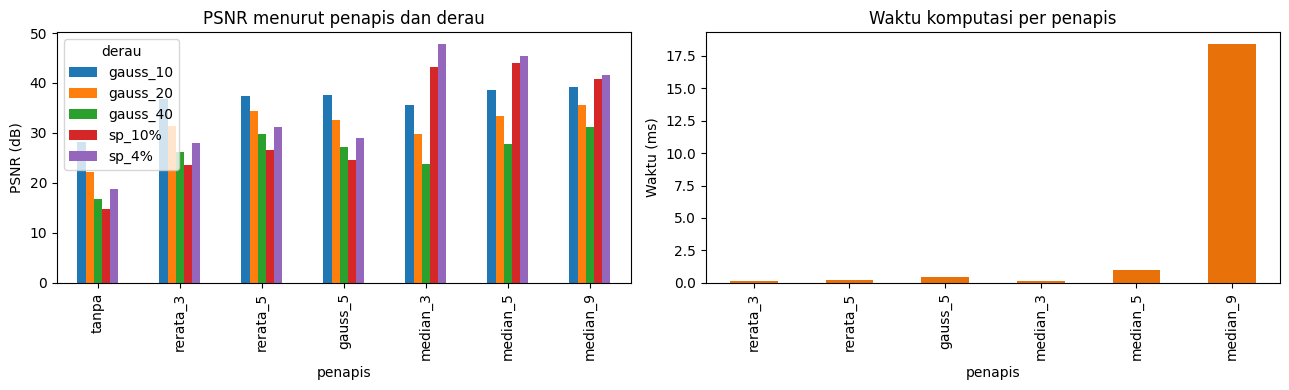

In [6]:
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20), "gauss_40": derau_gauss(bersih, 40),
         "sp_4%": derau_sp(bersih, 0.04), "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)), "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3), "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

print("Tabel 11: Gaussian 20 dan garam-merica 4%")
tab11 = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])].pivot(index="penapis", columns="derau", values=["PSNR_dB", "waktu_ms", "KB"])
display(tab11.reindex(["tanpa"] + list(penapis)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").reindex(["tanpa"] + list(penapis)).plot.bar(ax=ax[0])
ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR menurut penapis dan derau")
tabel[tabel.derau == "gauss_20"].set_index("penapis").waktu_ms.reindex(list(penapis)).plot.bar(ax=ax[1], color="#e8710a")
ax[1].set_ylabel("Waktu (ms)"); ax[1].set_title("Waktu komputasi per penapis")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr_waktu.png", dpi=110); plt.show()

## Kode 4.3: pengaruh ukuran kernel median pada bercak kecil (20 citra ringan)

,dI,KB
kernel,,
1,26.71,4.28
3,27.10,4.41
5,25.95,4.28
9,19.12,3.64
15,7.06,1.97


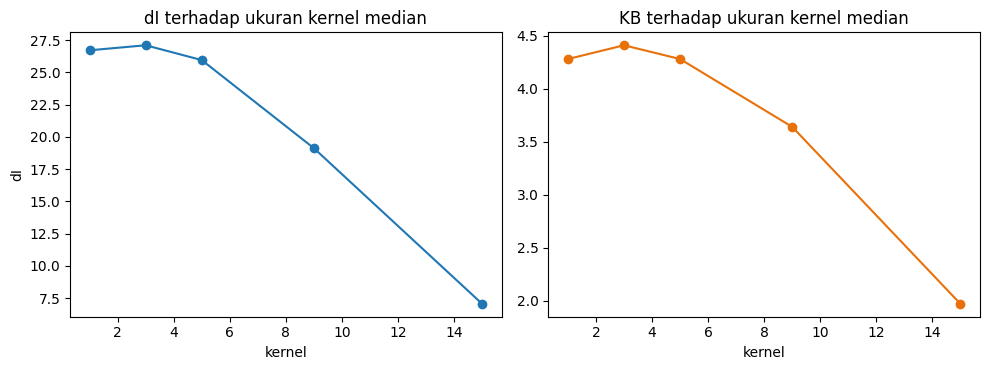

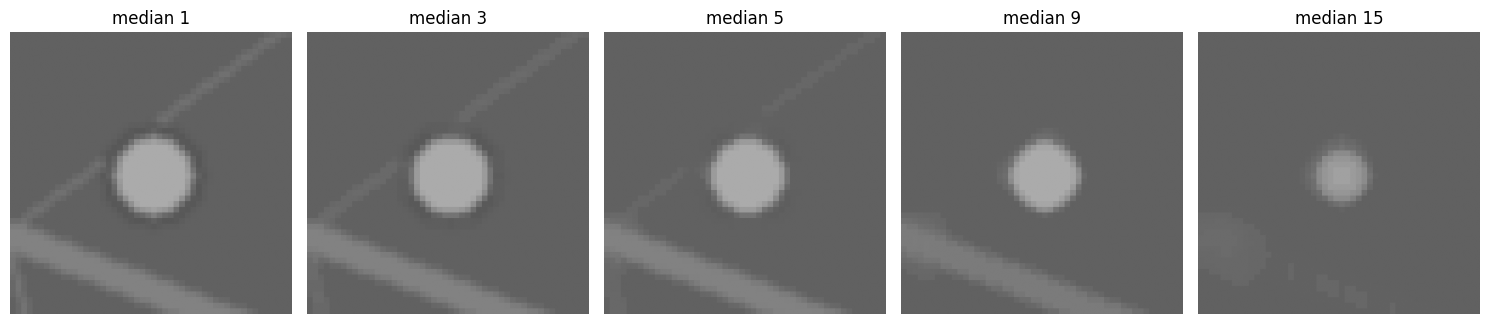

In [7]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g_ = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    _, md2, mb2 = muat(nm)
    for k in [1, 3, 5, 9, 15]:
        out = g_ if k == 1 else cv2.medianBlur(g_, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
display(rata); rata.to_csv("../hasil/b4_median_bercak_kecil.csv")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
rata.dI.plot(marker="o", ax=ax[0]); ax[0].set_title("dI terhadap ukuran kernel median"); ax[0].set_xlabel("kernel"); ax[0].set_ylabel("dI")
rata.KB.plot(marker="o", ax=ax[1], color="#e8710a"); ax[1].set_title("KB terhadap ukuran kernel median"); ax[1].set_xlabel("kernel")
plt.tight_layout(); plt.savefig("../hasil/b4_di_terhadap_kernel.png", dpi=110); plt.show()

# potongan bercak diperbesar (bercak ringan terkecil pada teh_021)
g21 = cv2.cvtColor(baca("../data/sintetis/bersih/teh_021.png"), cv2.COLOR_BGR2GRAY)
_, _, mb21 = muat("teh_021.png")
n_, lbl_, st_, cen_ = cv2.connectedComponentsWithStats((mb21 > 0).astype(np.uint8))
i_kecil = 1 + int(np.argmin(st_[1:, cv2.CC_STAT_AREA]))
cx, cy = map(int, cen_[i_kecil]); r = 25
y0, x0 = max(cy - r, 0), max(cx - r, 0)
potong, jd = [], []
for k in [1, 3, 5, 9, 15]:
    out = g21 if k == 1 else cv2.medianBlur(g21, k)
    potong.append(cv2.resize(out[y0:cy + r, x0:cx + r], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)); jd.append(f"median {k}")
tampil(potong, jd, ukuran=(15, 3.4)); plt.savefig("../hasil/b4_potongan_bercak.png", dpi=110); plt.show()

## Kode 4.4: urutan meredam dan menajamkan

In [8]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))      # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))      # redam dulu, lalu tajamkan
    print(f"{nm:8s}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f}, sigma_latar={A[latar].std():.1f} | "
          f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f}, sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.42, sigma_latar=7.7 | redam->tajam PSNR=30.22, sigma_latar=8.2
Median  : tajam->redam PSNR=30.15, sigma_latar=8.1 | redam->tajam PSNR=31.10, sigma_latar=7.2


## Langkah 4.6: penapisan derau sensor bawaan (12 citra kondisi normal)

In [9]:
normal = label[label.kondisi_cahaya == "normal"].nama_file.tolist()
print(len(normal), "citra normal")
kandidat = {"tanpa": lambda x: x, "rerata_3": lambda x: cv2.blur(x, (3, 3)),
            "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
            "median_3": lambda x: cv2.medianBlur(x, 3), "median_5": lambda x: cv2.medianBlur(x, 5)}
baris = []
for nm in normal:
    asli = baca(f"../data/sintetis/citra/{nm}")
    ref = baca(f"../data/sintetis/bersih/{nm}")
    baris.append([nm] + [cv2.PSNR(ref, f(asli)) for f in kandidat.values()])
psnr12 = pd.DataFrame(baris, columns=["citra"] + list(kandidat)).set_index("citra").round(2)
display(psnr12)
print("Rerata PSNR (dB):"); print(psnr12.mean().round(2))
psnr12.to_csv("../hasil/b4_psnr_12_normal.csv")

# P4.6: perkiraan jumlah perkalian konvolusi manual kernel 5 x 5
for w, h in [(4000, 3000), (640, 480)]:
    print(f"{w}x{h}: {w * h * 25:,} perkalian")
print("rasio:", round(4000 * 3000 / (640 * 480), 1), "kali")

12 citra normal


,tanpa,rerata_3,gauss_5,median_3,median_5
citra,,,,,
teh_001.png,28.30,37.09,37.93,35.72,38.82
teh_006.png,25.31,34.41,35.41,32.87,36.36
teh_011.png,28.10,36.76,37.52,35.51,38.60
teh_016.png,27.33,36.21,37.09,34.81,38.06
teh_021.png,26.73,35.64,36.54,34.21,37.52
teh_026.png,30.36,38.58,39.14,37.60,40.22
teh_031.png,30.79,39.01,39.59,38.02,40.61
teh_036.png,30.28,38.55,39.13,37.54,40.10
teh_041.png,27.21,35.91,36.67,34.60,37.52


Rerata PSNR (dB):
tanpa       28.61
rerata_3    37.12
gauss_5     37.82
median_3    35.94
median_5    38.77
dtype: float64
4000x3000: 300,000,000 perkalian
640x480: 7,680,000 perkalian
rasio: 39.1 kali
